# 03 — Twisted bilayer graphene: model, bands, screening, band-matrix G0W self-energy, spectral function

Sample: one valley of the Bistritzer–MacDonald/Koshino continuum model (pybandstructure `koshino`),
$\theta_{\rm TBG}=1.20^\circ$, $u_{AB}=117$ meV, $u_{AA}=0.7u_{AB}$, $\hbar v=0.657$ eV nm, charge neutrality
(the parameters of Wei *et al.*, PRB **112**, 155157). Stack: SLG tip | 1 nm hBN | TBG (vacuum vdW gap) | hBN.

Chain (`docs/notes.pdf`, Secs. 3–6):
$H(\mathbf{k})\to\{\xi_{n\mathbf{k}},u_{n\mathbf{k}}\}\to\rho^\ell_{nm}(\mathbf{k},\mathbf{q})\to\chi^0_{\ell\ell'}\to W\to\Sigma_{nn'}(\mathbf{k},\varepsilon)\to A_{nn'}(\mathbf{k},\varepsilon)$.

> Numerical settings here (`N_SITES = 18`, i.e. $18\times18$ k and q meshes) run in a few minutes.
> Production runs use `N_SITES = 24`–`36`; the paper uses $120\times120$.

In [1]:
import sys, os, time
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
# os.environ["PYBANDSTRUCTURE_PATH"] = "/path/to/bandstructure-calculation"   # if not installed
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from g0w.models import tbg_model as tm, tbg_stack as tst, tbg_self_energy as tse
from g0w import spectral, qtm
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

N_SITES = 18          # k/q mesh N_SITES x N_SITES
N_BANDS = 4           # bands kept on each side of charge neutrality (8 in total)
params = tm.TBGParams(theta_deg=1.20, uAB=0.117, uAA_ratio=0.7, n_sites=N_SITES, n_bands=N_BANDS, filling=0.0)
print(params.label()); print(f"G_moire = {params.G_moire:.4f} nm^-1, alpha = {params.alpha:.3f}, eta = {params.eta*1e3:.2f} meV")

TBG theta=1.2deg, uAB=117 meV, filling=0, n_sites=18, 8 bands
G_moire = 0.6177 nm^-1, alpha = 0.564, eta = 0.71 meV


## 1. Continuum model and band structure

In the plane-wave basis $\mathbf{k}+\mathbf{G}$ ($|\mathbf{G}|\le 3|\mathbf{G}_M|$, 37 shells) the Hamiltonian is
$H_{\mathbf{G}\mathbf{G}'}(\mathbf{k})=\delta_{\mathbf{G}\mathbf{G}'}\,\mathrm{diag}\big(h_t(\mathbf{k}+\mathbf{G}),h_b(\mathbf{k}+\mathbf{G})\big)+T_{\mathbf{G}-\mathbf{G}'}$,
with rotated Dirac blocks centred at the moiré $\kappa$ points $K_1$ (top) and $K_2$ (bottom) and the three
interlayer hoppings $T_j=u_{AA}\sigma_0+u_{AB}(\ldots)$. Only the 8 bands closest to neutrality are kept.

  TBG theta=1.2deg, uAB=117 meV, filling=0, n_sites=18, 8 bands
  n_k = 324, n_q = 324, n_G = 1, G_moire = 0.6177 nm^-1
  alpha = 0.5640, v_n = 0.0103 eV nm, eta = 0.708 meV
  mu = +1.810 meV   [12.6 s]
    theta = 1.2 deg, alpha = 0.5640: FLAT-BAND regime
    central bands (3, 4): BW = 24.9 / 23.9 meV
    gap to nearest remote: conduction +44.0 meV, valence +45.5 meV
    all computed bands span [-327, +324] meV about mu
    eta = 0.71 meV (heuristic 0.71, mesh floor 0.35)
top/bottom Dirac points (model frame, nm^-1): [-0.3088  0.1783] [-0.3088 -0.1783]


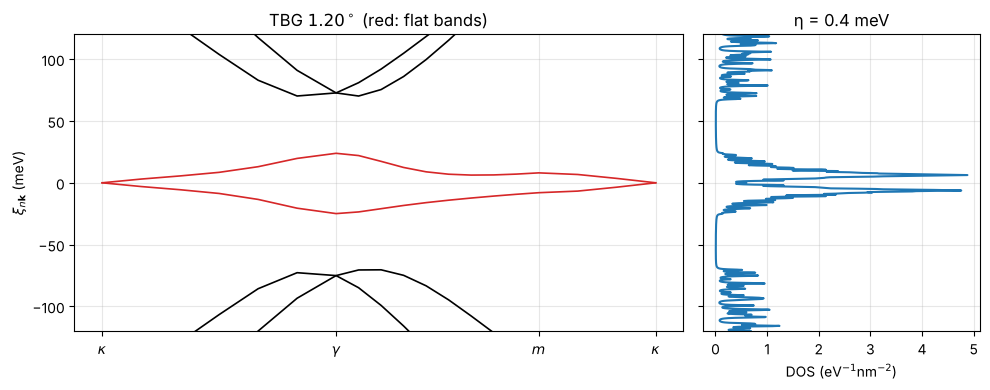

In [2]:
t0 = time.time()
tbg = tm.build_tbg(params, verbose=True)
print(tm.regime_summary(tbg))
bs = tbg["crystal"].band_structure
path = tm.path_indices(tbg, ("K", "Gamma", "M", "K"))
E = np.asarray(bs.energies) - tbg["mu"]
fr = tm.model_frame(tbg)
print("top/bottom Dirac points (model frame, nm^-1):", np.round(fr["K_top"], 4), np.round(fr["K_bot"], 4))

eps_dos = np.linspace(-0.12, 0.12, 961)
dos = tm.density_of_states(tbg, eps_dos, eta=0.4e-3)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw=dict(width_ratios=[2.2, 1]), sharey=True)
for n in range(E.shape[0]):
    ax[0].plot(path["x"], E[n, path["indices"]] * 1e3, color="C3" if n in (N_BANDS - 1, N_BANDS) else "k", lw=1.2)
ax[0].set_xticks(path["x"][path["vertices"]]); ax[0].set_xticklabels([r"$\kappa$", r"$\gamma$", r"$m$", r"$\kappa$"])
ax[0].set_ylabel(r"$\xi_{n\mathbf{k}}$ (meV)"); ax[0].set_ylim(-120, 120); ax[0].set_title(r"TBG $1.20^\circ$ (red: flat bands)")
ax[1].plot(dos, eps_dos * 1e3); ax[1].set_xlabel(r"DOS (eV$^{-1}$nm$^{-2}$)"); ax[1].set_title("η = 0.4 meV")
plt.tight_layout(); plt.show()

## 2. Layer-resolved form factors $\rho^\ell_{nm}(\mathbf{k},\mathbf{q})=\langle\mathbf{k} n|\rho_\ell(\mathbf{q})|\mathbf{k}+\mathbf{q}\,m\rangle$

`densityL[l, n, m, k, q, G]` (here head only, $G=0$). Completeness: at $\mathbf{q}=0$ the two layer
projectors add up to the identity, $\sum_\ell\rho^\ell_{nm}(\mathbf{k},0)=\delta_{nm}$.

In [3]:
lh = tm.build_layer_helper(tbg)
dL = np.asarray(lh.densityL)
q0 = int(np.argmin(np.linalg.norm(np.asarray(tbg["q_sample"].coords), axis=1)))
comp = dL[0, :, :, :, q0, 0] + dL[1, :, :, :, q0, 0]
print("completeness  max |sum_l rho^l(k,0) - 1| =", np.max(np.abs(comp - np.eye(comp.shape[0])[:, :, None])))
ki = path["indices"][0]                                     # kappa point
print("top-layer weight of the 8 bands at kappa_top:", np.round(dL[0, np.arange(8), np.arange(8), ki, q0, 0].real, 3))

  densityL (2, 8, 8, 324, 324, 1)  [56.1 s, 0.21 GB]
completeness  max |sum_l rho^l(k,0) - 1| = 1.0460900375226853e-14
top-layer weight of the 8 bands at kappa_top: [0.385 0.385 0.677 0.495 0.495 0.675 0.386 0.386]


## 3. Polarizability and screened interaction of the stack

$\chi^0_{\ell\ell'}(\mathbf{q},\omega)=\frac{g}{A}\sum_{nm\mathbf{k}}\frac{f_{n\mathbf{k}}-f_{m\mathbf{k}+\mathbf{q}}}{\omega+i\eta+\xi_{n\mathbf{k}}-\xi_{m\mathbf{k}+\mathbf{q}}}\rho^\ell_{nm}(\rho^{\ell'}_{nm})^*$ (2×2, sample),
the tip contributes the analytic bubble of charge-neutral graphene (interband only), and
$\varepsilon=1-V\chi^0$, $W=\varepsilon^{-1}V$ are $3\times3$ in sheet space at each $(\mathbf{q},\omega)$.

chi0 and W on 324 q x 320 w: 72.4 s;   stack: d_tip=1 nm, tip n=0 nm^-2, ungated, eps=(6.41,3), eps_gap=1
spectral density PSD: True   W symmetric: 6.81003856870683e-16


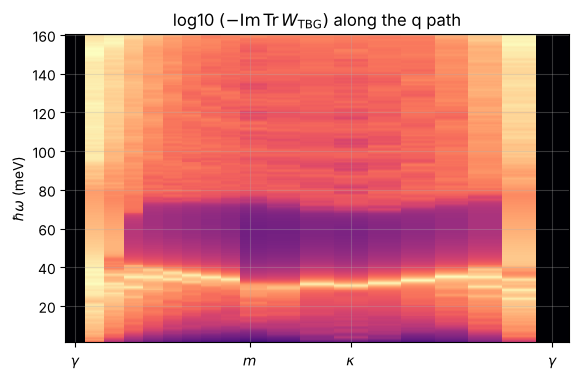

In [4]:
eta = params.eta
omega = np.linspace(2 * eta, 0.16, 320)           # real frequencies; +i eta added inside
t0 = time.time()
chi_tbg = tm.chi0_tbg(lh, omega + 1j * eta, verbose=False)
cfg = tst.TBGSLGConfig(tbg=params, d_tip=1.0, n_tip=0.0, chi_on_tip=True)
q_coords = np.asarray(tbg["q_sample"].coords)
eps_l, V, W = tst.build_stack_eps_W(cfg, q_coords, omega, chi_tbg, verbose=False)
print(f"chi0 and W on {q_coords.shape[0]} q x {omega.size} w: {time.time()-t0:.1f} s;   stack: {cfg.label()}")
S = tse.sample_spectral_density(W, hermitian=True)            # (n_q, n_w, 2, 2), Hermitian PSD
ev = np.linalg.eigvalsh(S)
print("spectral density PSD:", ev.min() > -1e-10 * np.abs(ev).max(), "  W symmetric:",
      np.max(np.abs(W - np.swapaxes(W, -1, -2))) / np.max(np.abs(W)))

# loss along the q path gamma -> m -> kappa -> gamma (one direction per point, no multivaluedness)
qpath = tbg["q_sample"].contour([r"$\Gamma$", r"$M$", r"$K$", r"$\Gamma$"])
L = -np.imag(np.trace(W[:, :, 1:, 1:], axis1=2, axis2=3))[qpath["indices"]]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.pcolormesh(qpath["x"], omega * 1e3, np.log10(np.maximum(L.T, 1e-3)), shading="auto", cmap="magma")
ax.set_xticks(qpath["x"][qpath["vertices"]]); ax.set_xticklabels([r"$\gamma$", r"$m$", r"$\kappa$", r"$\gamma$"])
ax.set_ylabel(r"$\hbar\omega$ (meV)"); ax.set_title(r"log10 $(-\mathrm{Im\,Tr}\,W_{\rm TBG})$ along the q path")
plt.show()

**Both valleys.** pybandstructure diagonalises valley $K$ only. Time reversal maps valley $K$ at $\mathbf{q}$ onto
$K'$ at $-\mathbf{q}$ with the $2\times2$ layer matrix transposed, so the spin- and valley-summed response is
$\chi^0(\mathbf{q})=\tfrac12[X(\mathbf{q})+X(-\mathbf{q})^T]$ with $X=g\chi^K$, $g=4$ (`chi0_tbg`). Since the bands of one
valley are not inversion symmetric, $E_K(\mathbf{k})\neq E_K(-\mathbf{k})$, both terms are needed; the result obeys the
Onsager relation $\chi^0(\mathbf{q})=\chi^0(-\mathbf{q})^T$, checked below on the whole mesh (notes Sec. 4.1).

In [5]:
mq = tm.minus_q_index(tbg)
ok = ~mq["on_boundary"]
viol = np.max(np.abs(chi_tbg[ok] - np.swapaxes(chi_tbg[mq["index"]][ok], 1, 2))) / np.max(np.abs(chi_tbg))
print(f"Onsager relation chi0(q) = chi0(-q)^T: max relative violation {viol:.1e} "
      f"({ok.sum()} of {ok.size} q points; the rest lie on the zone boundary)")

Onsager relation chi0(q) = chi0(-q)^T: max relative violation 0.0e+00 (311 of 324 q points; the rest lie on the zone boundary)


The nearly dispersionless bright branch at $\approx 30$–$40$ meV is the flat-band plasmon in the gap between the
flat-band and the remote-band particle–hole continua (Wei *et al.* Fig. 5).

## 4. Band-matrix G0W self-energy

$$\Sigma_{nn'}(\mathbf{k},\varepsilon)=-\sum_{\mathbf{q}}w_{\mathbf{q}}\sum_m\sum_{ab}\rho^a_{nm}(\mathbf{k},\mathbf{q})\,[\rho^b_{n'm}(\mathbf{k},\mathbf{q})]^*\int_0^{\omega_{\max}}\!d\omega\,S_{ab}(\mathbf{q},\omega)\,\mathcal D_m(\omega,\varepsilon),$$
$\mathcal D_m=\frac{\Theta(\xi_m)}{\omega+\xi_m-\varepsilon-i\eta}+\frac{\Theta(-\xi_m)}{-\omega+\xi_m-\varepsilon-i\eta}$, $\xi_m=\xi_{m,\mathbf{k}+\mathbf{q}}$,
$w_{\mathbf{q}}=d^2q/(2\pi)^2$ weight (no degeneracy: the internal line carries the external flavour).
With $S$ Hermitian PSD the anti-Hermitian part of $\Sigma$ is negative semidefinite (causality).

resolvent kernel tabulated: 1.9 s (10742 u points)
Sigma (8x8 bands, 601 energies) in 26.3 s;  kernel vs direct: 7.1e-05;  passive: True
||off-diagonal|| / ||diagonal|| at kappa_top: 0.306


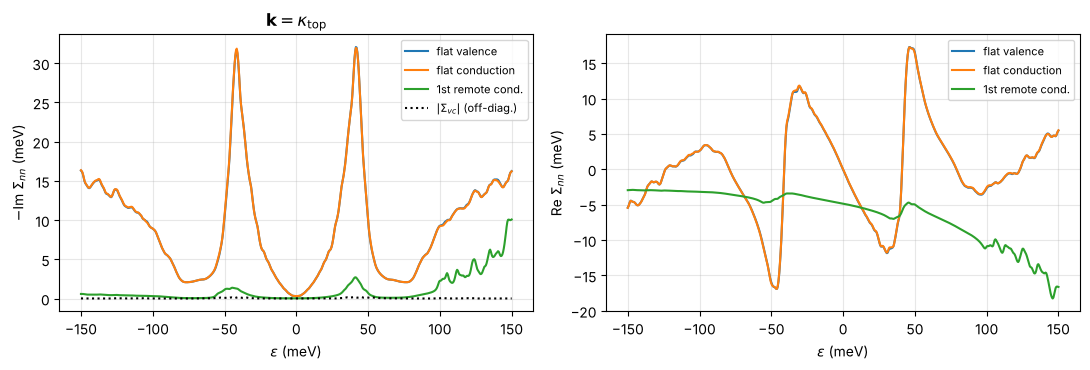

In [6]:
eps_v = np.linspace(-0.15, 0.15, 601)
t0 = time.time()
kernel = tse.build_kernel_tbg(tbg, S, omega, eps_v, eta_self=eta)
print(f"resolvent kernel tabulated: {time.time()-t0:.1f} s ({kernel.u.size} u points)")
bands = list(range(2 * N_BANDS))
k_kappa = path["indices"][0]
k_m = path["indices"][path["vertices"][2]]
t0 = time.time()
Sig_kappa = tse.sigma_band_matrix(tbg, lh, k_kappa, bands, eps_v, kernel=kernel)
Sig_dir = tse.sigma_band_matrix(tbg, lh, k_kappa, bands, eps_v, S_q=S, omega_grid=omega, eta_self=eta)
print(f"Sigma (8x8 bands, {eps_v.size} energies) in {time.time()-t0:.1f} s;  kernel vs direct: "
      f"{np.max(np.abs(Sig_kappa - Sig_dir))/np.max(np.abs(Sig_dir)):.1e};  passive: {spectral.is_passive(Sig_kappa)}")
off = np.linalg.norm(Sig_kappa - Sig_kappa * np.eye(8)[:, :, None]) / np.linalg.norm(Sig_kappa * np.eye(8)[:, :, None])
print(f"||off-diagonal|| / ||diagonal|| at kappa_top: {off:.3f}")

ic = N_BANDS                                     # flat conduction band
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for n, lab in ((N_BANDS - 1, "flat valence"), (N_BANDS, "flat conduction"), (N_BANDS + 1, "1st remote cond.")):
    ax[0].plot(eps_v * 1e3, -Sig_kappa[n, n].imag * 1e3, label=lab)
    ax[1].plot(eps_v * 1e3, Sig_kappa[n, n].real * 1e3, label=lab)
ax[0].plot(eps_v * 1e3, np.abs(Sig_kappa[N_BANDS - 1, N_BANDS]) * 1e3, "k:", label=r"$|\Sigma_{vc}|$ (off-diag.)")
ax[0].set_ylabel(r"$-$Im $\Sigma_{nn}$ (meV)"); ax[1].set_ylabel(r"Re $\Sigma_{nn}$ (meV)")
for a in ax: a.set_xlabel(r"$\varepsilon$ (meV)"); a.legend(fontsize=8)
ax[0].set_title(r"$\mathbf{k}=\kappa_{\rm top}$"); plt.tight_layout(); plt.show()

Peaks of $-\mathrm{Im}\,\Sigma$ at $|\varepsilon|\approx 40$ meV: emission of the flat plasmon
($\xi_{\rm flat}+\hbar\omega_{\rm pl}$), the origin of the satellites. Hartree and Fock terms are not included:
as in Wei *et al.* (Sec. IV B) they are neglected because they only give a Hermitian, band-renormalising
self-energy (notes Sec. 5.5).

## 5. Spectral function along the high-symmetry path

Matrix Dyson equation $G=[(\varepsilon+i\eta_{\rm qp})-\mathrm{diag}(\xi)-\Sigma]^{-1}$ and
$A=i(G-G^\dagger)/2\pi$; we plot $\mathrm{Tr}\,A(\mathbf{k},\varepsilon)$ and compare the band-diagonal approximation.

19 k points: 43.7 s


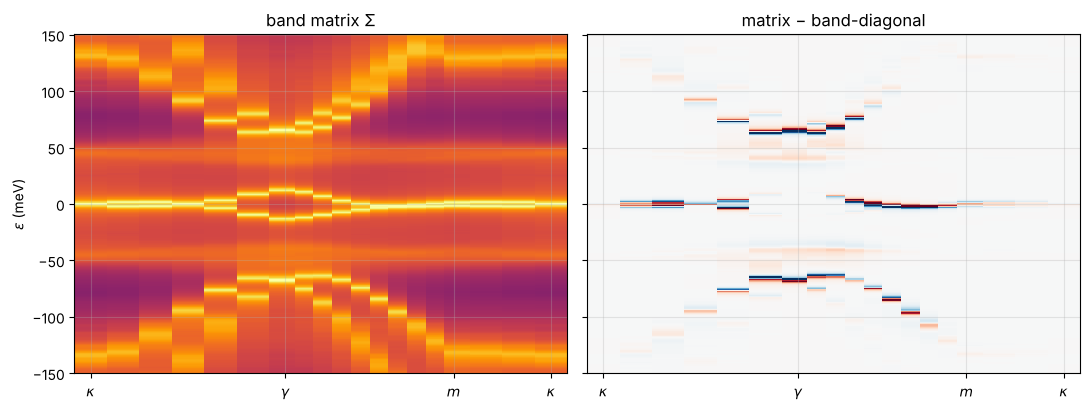

In [7]:
t0 = time.time()
k_path = path["indices"]
TrA = np.zeros((k_path.size, eps_v.size)); TrA_diag = np.zeros_like(TrA)
for i, ki in enumerate(k_path):
    Sg = tse.sigma_band_matrix(tbg, lh, int(ki), bands, eps_v, kernel=kernel)
    xi = E[bands, int(ki)]
    TrA[i] = np.real(np.trace(spectral.spectral_function_matrix(eps_v, xi, Sg, eta_qp=1e-3), axis1=1, axis2=2))
    TrA_diag[i] = np.real(np.trace(spectral.spectral_function_matrix(eps_v, xi, Sg * np.eye(8)[:, :, None], eta_qp=1e-3), axis1=1, axis2=2))
print(f"{k_path.size} k points: {time.time()-t0:.1f} s")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for a, y, t in ((ax[0], TrA, "band matrix Σ"), (ax[1], TrA - TrA_diag, "matrix − band-diagonal")):
    if a is ax[0]:
        a.pcolormesh(path["x"], eps_v * 1e3, np.log10(y.T + 1e-2), shading="auto", cmap="inferno", vmin=-2, vmax=2.5)
    else:
        lim = np.percentile(np.abs(y), 99.5)
        a.pcolormesh(path["x"], eps_v * 1e3, y.T, shading="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    a.set_xticks(path["x"][path["vertices"]]); a.set_xticklabels([r"$\kappa$", r"$\gamma$", r"$m$", r"$\kappa$"]); a.set_title(t)
ax[0].set_ylabel(r"$\varepsilon$ (meV)"); plt.tight_layout(); plt.show()

Bright lines: quasiparticle bands (shifted by Re Σ); faint flat bands at $\approx\pm(40$–$50)$ meV: plasmon
satellites. The right panel shows where the interband (off-diagonal) self-energy redistributes weight;
it is largest where bands are close, i.e. inside the flat-band manifold.

## 6. Variations

* **Gates**: `TBGSLGConfig(top_gate_d=..., bottom_gate_d=...)` (dual gates 1 nm away reduce the in-phase
  channel, Wei *et al.* Sec. V B).
* **Inert tip**: `chi_on_tip=False` measures the tip back-action on the sample self-energy.
* **Doped TBG**: set `filling` and run `tm.apply_hartree(tbg, eps_hartree)` before building `lh`
  (needs the pybandstructure development version: README, Section 1).
* **Magic angle** $1.07^\circ$ or other $u_{AB}$: change `TBGParams`; check `tm.regime_summary`.